<a href="https://colab.research.google.com/github/MonaMobeen/-Jaw-Dropping-Thesaurus/blob/master/01_Dataset_Acquisition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen
from datetime import datetime, timezone
import hashlib
import json
import time
import pandas as pd
import sklearn

# Official UCI dataset source
url = (
    "https://archive.ics.uci.edu/static/public/222/"
    "bank+marketing.zip"
)

# Folder for original dataset
raw_dir = Path("data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

# Download with retry
for attempt in range(3):
    try:
        archive = urlopen(url, timeout=60).read()
        break
    except Exception as error:
        if attempt == 2:
            raise RuntimeError(
                "Dataset download failed. Please try again."
            ) from error
        print(f"Download attempt {attempt + 1} failed. Retrying...")
        time.sleep(3)

# Open ZIP files
outer = ZipFile(BytesIO(archive))
inner = ZipFile(BytesIO(outer.read("bank-additional.zip")))

# Select the required full dataset
member = "bank-additional/bank-additional-full.csv"
raw = inner.read(member)

# Save original CSV
csv_path = raw_dir / "bank-additional-full.csv"
csv_path.write_bytes(raw)

# Read dataset
df = pd.read_csv(BytesIO(raw), sep=";")

# Verify dataset
assert df.shape == (41188, 21), "Unexpected dataset shape!"
assert set(df["y"].unique()) == {"yes", "no"}, "Unexpected target values!"

# Add record ID as metadata
df.insert(0, "record_id", range(len(df)))

# Calculate SHA-256
file_hash = hashlib.sha256(raw).hexdigest()

# Create dataset manifest
manifest = {
    "source": url,
    "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
    "archive_member": member,
    "archive_size_bytes": len(archive),
    "csv_size_bytes": len(raw),
    "sha256": file_hash,
    "rows": len(df),
    "raw_columns": 21,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "retry_policy": "3 attempts, 60-second timeout, 3-second delay"
}

Path("data_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("Target counts:")
print(df["y"].value_counts())
print("SHA-256:", file_hash)


Dataset downloaded successfully!
Dataset shape: (41188, 22)
Target counts:
y
no     36548
yes     4640
Name: count, dtype: int64
SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8


In [2]:

# Find the official data dictionary inside the ZIP
names_file = "bank-additional/bank-additional-names.txt"

# Read its contents
dictionary = inner.read(names_file).decode("utf-8")

# Display the official information
print(dictionary)


﻿Citation Request:
  This dataset is publicly available for research. The details are described in [Moro et al., 2014]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, http://dx.doi.org/10.1016/j.dss.2014.03.001

  Available at: [pdf] http://dx.doi.org/10.1016/j.dss.2014.03.001
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2014-dss.txt

1. Title: Bank Marketing (with social/economic context)

2. Sources
   Created by: Sérgio Moro (ISCTE-IUL), Paulo Cortez (Univ. Minho) and Paulo Rita (ISCTE-IUL) @ 2014
   
3. Past Usage:

  The full dataset (bank-additional-full.csv) was described and analyzed in:

  S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems (2014), doi:10.1016/j.dss.2014.03.001.
 
4. Relevant Information:

   This

In [3]:
print(dictionary)

﻿Citation Request:
  This dataset is publicly available for research. The details are described in [Moro et al., 2014]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, http://dx.doi.org/10.1016/j.dss.2014.03.001

  Available at: [pdf] http://dx.doi.org/10.1016/j.dss.2014.03.001
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2014-dss.txt

1. Title: Bank Marketing (with social/economic context)

2. Sources
   Created by: Sérgio Moro (ISCTE-IUL), Paulo Cortez (Univ. Minho) and Paulo Rita (ISCTE-IUL) @ 2014
   
3. Past Usage:

  The full dataset (bank-additional-full.csv) was described and analyzed in:

  S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems (2014), doi:10.1016/j.dss.2014.03.001.
 
4. Relevant Information:

   This

In [4]:

# Display all original dataset columns
print("Original Dataset Columns:")

for column in df.columns:
    print(column)


Original Dataset Columns:
record_id
age
job
marital
education
default
housing
loan
contact
month
day_of_week
duration
campaign
pdays
previous
poutcome
emp.var.rate
cons.price.idx
cons.conf.idx
euribor3m
nr.employed
y


In [5]:

# Target: what our model will predict
target = df["y"].copy()

# Set A: Conservative core features
set_a_features = [
    "age", "job", "marital", "education",
    "default", "housing", "loan",
    "contact", "month", "day_of_week",
    "pdays", "previous", "poutcome"
]

# Set B: Additional features
economic_features = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

# campaign includes the current call.
# Subtract 1 to get previous attempts.
df["prior_attempts"] = df["campaign"] - 1

set_b_features = (
    set_a_features
    + ["prior_attempts"]
    + economic_features
)

# Create feature datasets
X_A = df[set_a_features].copy()
X_B = df[set_b_features].copy()

# Safety checks: forbidden columns must not be included
forbidden = {"duration", "campaign", "y", "record_id"}

assert not forbidden.intersection(X_A.columns)
assert not forbidden.intersection(X_B.columns)

# Verify target
assert len(target) == len(X_A) == len(X_B)

print("Set A shape:", X_A.shape)
print("Set B shape:", X_B.shape)
print("Target shape:", target.shape)

print("\nSet A features:")
print(list(X_A.columns))

print("\nSet B features:")
print(list(X_B.columns))

print("\nAll safety checks passed!")


Set A shape: (41188, 13)
Set B shape: (41188, 19)
Target shape: (41188,)

Set A features:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'previous', 'poutcome']

Set B features:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'previous', 'poutcome', 'prior_attempts', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

All safety checks passed!


In [6]:

from pathlib import Path

contract = """
# Feature Availability Contract

## Project
Bank Marketing - Campaign Intelligence

## Target
y: Predict whether a customer subscribes to a term deposit.

## Set A - Conservative Core
Allowed features:
- Customer attributes
- Previous campaign history
- Planned contact information

Assumption:
Contact month, weekday and communication type
are known before the call is made.

## Set B - Extended Feature Set
Includes Set A plus:
- prior_attempts = campaign - 1
- Five social and economic indicators

Important:
Set B is for comparison and sensitivity analysis.
Availability of these extra features must be
verified before using Set B in a real service.

## Forbidden Inputs
- duration: Known only after the call.
- y: Prediction target, not an input.
- record_id: Metadata only.
- campaign: Includes the current call.
  Use campaign - 1 in Set B instead.

## Special Value
pdays = 999 means the customer was not
previously contacted.

## Default Model Policy
Set A is the conservative default feature set.
"""

Path("availability_contract.md").write_text(
    contract.strip(),
    encoding="utf-8"
)

print("Availability contract created successfully!")
print(Path("availability_contract.md").read_text())


Availability contract created successfully!
# Feature Availability Contract

## Project
Bank Marketing - Campaign Intelligence

## Target
y: Predict whether a customer subscribes to a term deposit.

## Set A - Conservative Core
Allowed features:
- Customer attributes
- Previous campaign history
- Planned contact information

Assumption:
Contact month, weekday and communication type
are known before the call is made.

## Set B - Extended Feature Set
Includes Set A plus:
- prior_attempts = campaign - 1
- Five social and economic indicators

Important:
Set B is for comparison and sensitivity analysis.
Availability of these extra features must be
verified before using Set B in a real service.

## Forbidden Inputs
- duration: Known only after the call.
- y: Prediction target, not an input.
- record_id: Metadata only.
- campaign: Includes the current call.
  Use campaign - 1 in Set B instead.

## Special Value
pdays = 999 means the customer was not
previously contacted.

## Default Model Pol

In [7]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score


In [8]:

# Convert target into numbers
y_binary = (target == "yes").astype(int)

# Same split for both experiments
X_train, X_test, y_train, y_test = train_test_split(
    X_A,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 32950
Testing records: 8238


In [10]:

from sklearn.linear_model import LogisticRegression

def create_model_pipeline(X):
    # Identify numeric and categorical columns
    numeric_cols = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_cols = X.select_dtypes(
        include=["object"]
    ).columns.tolist()

    # Numeric preprocessing
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine both preprocessing branches
    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    # Complete preprocessing + model pipeline
    model = Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(max_iter=1000))
    ])

    return model


In [11]:

# Clean model: Set A features only
clean_model = create_model_pipeline(X_train)

clean_model.fit(X_train, y_train)

# Leakage model: Set A + duration
X_train_leak = X_train.copy()
X_test_leak = X_test.copy()

X_train_leak["duration"] = df.loc[
    X_train.index, "duration"
]

X_test_leak["duration"] = df.loc[
    X_test.index, "duration"
]

leakage_model = create_model_pipeline(X_train_leak)

leakage_model.fit(X_train_leak, y_train)

print("Both models trained successfully!")


Both models trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [12]:

# Get prediction probabilities
clean_predictions = clean_model.predict_proba(X_test)[:, 1]

leakage_predictions = leakage_model.predict_proba(
    X_test_leak
)[:, 1]

# Calculate Average Precision
clean_ap = average_precision_score(
    y_test, clean_predictions
)

leakage_ap = average_precision_score(
    y_test, leakage_predictions
)

print("LEAKAGE DEMO - DO NOT DEPLOY")
print("--------------------------------")
print(f"Clean Model Average Precision: {clean_ap:.4f}")
print(f"Leakage Model Average Precision: {leakage_ap:.4f}")


LEAKAGE DEMO - DO NOT DEPLOY
--------------------------------
Clean Model Average Precision: 0.4169
Leakage Model Average Precision: 0.5901


In [13]:

leakage_report = f"""
# Data Leakage Demonstration

**Status:** LEAKAGE DEMO - DO NOT DEPLOY

## Experiment
We compared two Logistic Regression models.

1. Clean Model: Set A features only.
2. Leakage Model: Set A features + duration.

## Results

| Model | Average Precision |
|---|---:|
| Clean Model | {clean_ap:.4f} |
| Leakage Model | {leakage_ap:.4f} |

Difference: {leakage_ap - clean_ap:.4f}

## Conclusion

The leakage model achieved a higher Average Precision
because it used duration, which is only known after
the call has ended.

Duration is therefore forbidden for the final
pre-call subscription prediction model.

The clean model is the valid experiment for this
comparison.

Note: This was a random split used only for the
leakage demonstration. Final evaluation will use
the assignment's fixed chronological partitions.
"""

Path("leakage_demo_report.md").write_text(
    leakage_report.strip(),
    encoding="utf-8"
)

print("Leakage report saved successfully!")
print(leakage_report)


Leakage report saved successfully!

# Data Leakage Demonstration

**Status:** LEAKAGE DEMO - DO NOT DEPLOY

## Experiment
We compared two Logistic Regression models.

1. Clean Model: Set A features only.
2. Leakage Model: Set A features + duration.

## Results

| Model | Average Precision |
|---|---:|
| Clean Model | 0.4169 |
| Leakage Model | 0.5901 |

Difference: 0.1731

## Conclusion

The leakage model achieved a higher Average Precision
because it used duration, which is only known after
the call has ended.

Duration is therefore forbidden for the final
pre-call subscription prediction model.

The clean model is the valid experiment for this
comparison.

Note: This was a random split used only for the
leakage demonstration. Final evaluation will use
the assignment's fixed chronological partitions.



In [14]:
import pandas as pd

data_dictionary = [
    ["age", "Customer age", "Numeric", "Set A", "Available before call"],
    ["job", "Customer job type", "Categorical", "Set A", "Available before call"],
    ["marital", "Marital status", "Categorical", "Set A", "Available before call"],
    ["education", "Education level", "Categorical", "Set A", "Available before call"],
    ["default", "Has credit in default?", "Categorical", "Set A", "Available before call"],
    ["housing", "Has housing loan?", "Categorical", "Set A", "Available before call"],
    ["loan", "Has personal loan?", "Categorical", "Set A", "Available before call"],
    ["contact", "Contact communication type", "Categorical", "Set A", "Assumed known before call"],
    ["month", "Last contact month", "Categorical", "Set A", "Assumed known before call"],
    ["day_of_week", "Last contact day", "Categorical", "Set A", "Assumed known before call"],
    ["duration", "Last call duration in seconds", "Numeric", "Excluded", "Known only after call; leakage risk"],
    ["campaign", "Contacts during current campaign, including current call", "Numeric", "Excluded", "Use campaign - 1 as prior_attempts"],
    ["pdays", "Days since previous campaign contact; 999 means never contacted", "Numeric", "Set A", "Previous campaign history"],
    ["previous", "Contacts before current campaign", "Numeric", "Set A", "Previous campaign history"],
    ["poutcome", "Previous campaign outcome", "Categorical", "Set A", "Previous campaign history"],
    ["emp.var.rate", "Employment variation rate", "Numeric", "Set B only", "Timing availability needs verification"],
    ["cons.price.idx", "Consumer price index", "Numeric", "Set B only", "Timing availability needs verification"],
    ["cons.conf.idx", "Consumer confidence index", "Numeric", "Set B only", "Timing availability needs verification"],
    ["euribor3m", "Three-month Euribor rate", "Numeric", "Set B only", "Timing availability needs verification"],
    ["nr.employed", "Number of employees indicator", "Numeric", "Set B only", "Timing availability needs verification"],
    ["y", "Whether customer subscribed: yes/no", "Categorical", "Target", "Prediction target"],
    ["record_id", "Unique row identifier added by us", "Integer", "Metadata", "Not a model feature"]
]

dictionary_df = pd.DataFrame(
    data_dictionary,
    columns=[
        "Column",
        "Meaning",
        "Data_Type",
        "Project_Role",
        "Availability_or_Reason"
    ]
)

dictionary_df.to_csv("data_dictionary.csv", index=False)

print("Data Dictionary created successfully!")
print("Total documented columns:", len(dictionary_df))
display(dictionary_df)

Data Dictionary created successfully!
Total documented columns: 22


,Column,Meaning,Data_Type,Project_Role,Availability_or_Reason
0,age,Customer age,Numeric,Set A,Available before call
1,job,Customer job type,Categorical,Set A,Available before call
2,marital,Marital status,Categorical,Set A,Available before call
3,education,Education level,Categorical,Set A,Available before call
4,default,Has credit in default?,Categorical,Set A,Available before call
5,housing,Has housing loan?,Categorical,Set A,Available before call
6,loan,Has personal loan?,Categorical,Set A,Available before call
7,contact,Contact communication type,Categorical,Set A,Assumed known before call
8,month,Last contact month,Categorical,Set A,Assumed known before call
9,day_of_week,Last contact day,Categorical,Set A,Assumed known before call


In [15]:
# Step 1: Define forbidden columns
forbidden_columns = {
    "duration",
    "campaign",
    "y",
    "record_id"
}

# Step 2: Check Set A
set_a_violations = forbidden_columns.intersection(X_A.columns)

# Step 3: Check Set B
set_b_violations = forbidden_columns.intersection(X_B.columns)

# Step 4: Run automated tests
assert len(set_a_violations) == 0, f"Set A contains forbidden columns: {set_a_violations}"
assert len(set_b_violations) == 0, f"Set B contains forbidden columns: {set_b_violations}"

assert "y" not in X_A.columns
assert "y" not in X_B.columns

assert "prior_attempts" in X_B.columns
assert "prior_attempts" not in X_A.columns

assert len(X_A) == len(target)
assert len(X_B) == len(target)

print("All Feature Safety Tests Passed!")
print("Set A features:", len(X_A.columns))
print("Set B features:", len(X_B.columns))
print("Forbidden columns found:", 0)

All Feature Safety Tests Passed!
Set A features: 13
Set B features: 19
Forbidden columns found: 0


In [16]:
temporal_review = """
# Temporal Availability Review

## Set A assumptions

- age, job, marital, education, default, housing, loan:
  Customer information assumed available before the call.

- pdays, previous, poutcome:
  Previous campaign history assumed available before the current call.

- contact, month, day_of_week:
  Assumed to represent planned contact information.
  This assumption requires verification in a real deployment.

## Set B assumptions

- prior_attempts:
  Derived as campaign - 1.
  Represents earlier contacts in the current campaign.

- emp.var.rate, cons.price.idx, cons.conf.idx,
  euribor3m, nr.employed:
  Economic indicators included for sensitivity analysis only.
  Their exact publication-time availability must be verified.

## Important restriction

- duration is known only after the call.
- duration must never be used as a pre-call prediction feature.
- Set A remains the default feature set.
- Set B is an experimental comparison until timing availability is verified.
"""

with open("temporal_availability_review.md", "w") as file:
    file.write(temporal_review)

print("Temporal availability review saved successfully!")

Temporal availability review saved successfully!


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

model_pipeline = Pipeline([
    ("preprocessing", numeric_pipeline),
    ("model", LogisticRegression(max_iter=1000))
])

print("Preprocessing and model pipeline created successfully!")

Preprocessing and model pipeline created successfully!


In [18]:
leakage_review = """
# Leakage Experiment Review

## Preliminary Results

Clean Model Average Precision: 0.4169
Leakage Model Average Precision: 0.5901

## Observation

The leakage model achieved higher Average Precision
because it included duration.

## Why This Is Invalid

Duration is only known after the call ends.
Our subscription prediction must happen before the call.

Therefore, duration is a forbidden feature.

## Experimental Limitation

The preliminary experiment used a random 80/20 split
instead of the required chronological split.

The random test partition included records from the
assignment's intended final-test period.

Therefore:
- These results are educational only.
- They are not official model evaluation results.
- The previous test partition cannot be described as untouched.
- Future experiments must follow the chronological
  development split and document this deviation.

## Deployment Decision

The leakage model must never be deployed.
"""

with open("leakage_experiment_review.md", "w") as file:
    file.write(leakage_review)

print("Leakage experiment review saved successfully!")

Leakage experiment review saved successfully!


In [19]:
import json

# Verify original dataset
assert len(df) == 41188, "Unexpected dataset size!"
assert "record_id" in df.columns, "record_id column missing!"

# Define chronological row boundaries
split_ranges = {
    "train": [0, 24712],
    "calibration": [24712, 28831],
    "policy_validation": [28831, 32950],
    "final_test": [32950, 41188]
}

# Create split manifest using original row IDs
split_manifest = {
    "project": "Bank Marketing - Campaign Intelligence",
    "split_method": "Chronological - no shuffle",
    "total_records": len(df),
    "splits": {}
}

for split_name, (start, end) in split_ranges.items():
    split_manifest["splits"][split_name] = {
        "start_position": start,
        "end_position_exclusive": end,
        "record_count": end - start,
        "record_ids": df["record_id"].iloc[start:end].tolist()
    }

# Save manifest
with open("split_manifest.json", "w") as file:
    json.dump(split_manifest, file, indent=4)

print("Chronological split manifest created!")
for name, details in split_manifest["splits"].items():
    print(name, ":", details["record_count"], "records")

Chronological split manifest created!
train : 24712 records
calibration : 4119 records
policy_validation : 4119 records
final_test : 8238 records


In [20]:
# Collect record IDs from all four splits
all_split_ids = []

for split_name, details in split_manifest["splits"].items():
    all_split_ids.extend(details["record_ids"])

# Check total records
assert len(all_split_ids) == 41188

# Check duplicate records
assert len(all_split_ids) == len(set(all_split_ids))

# Check that every original record is included
assert sorted(all_split_ids) == sorted(df["record_id"].tolist())

# Check chronological order
assert all_split_ids == sorted(all_split_ids)

print("All Split Verification Tests Passed!")
print("Total records:", len(all_split_ids))
print("Duplicate records:", len(all_split_ids) - len(set(all_split_ids)))
print("Missing records:", len(set(df["record_id"]) - set(all_split_ids)))
print("Chronological order: Preserved")

All Split Verification Tests Passed!
Total records: 41188
Duplicate records: 0
Missing records: 0
Chronological order: Preserved


In [21]:
# Create row-position slices using original chronological order

train_df = df.iloc[0:24712].copy()

calibration_df = df.iloc[24712:28831].copy()

policy_validation_df = df.iloc[28831:32950].copy()

final_test_df = df.iloc[32950:41188].copy()


# Separate features and target for Set A

X_train = train_df[set_a_features].copy()
y_train = (train_df["y"] == "yes").astype(int)

X_calibration = calibration_df[set_a_features].copy()
y_calibration = (calibration_df["y"] == "yes").astype(int)

X_policy_validation = policy_validation_df[set_a_features].copy()
y_policy_validation = (policy_validation_df["y"] == "yes").astype(int)

X_final_test = final_test_df[set_a_features].copy()
y_final_test = (final_test_df["y"] == "yes").astype(int)


# Display shapes

print("TRAINING:", X_train.shape, y_train.shape)
print("CALIBRATION:", X_calibration.shape, y_calibration.shape)
print("POLICY VALIDATION:", X_policy_validation.shape, y_policy_validation.shape)
print("FINAL TEST:", X_final_test.shape, y_final_test.shape)

TRAINING: (24712, 13) (24712,)
CALIBRATION: (4119, 13) (4119,)
POLICY VALIDATION: (4119, 13) (4119,)
FINAL TEST: (8238, 13) (8238,)


In [22]:
# Check target distribution in all four datasets

splits = {
    "Training": y_train,
    "Calibration": y_calibration,
    "Policy Validation": y_policy_validation,
    "Final Test": y_final_test
}

for split_name, target_values in splits.items():

    print("\n", split_name)
    print("-" * 35)

    counts = target_values.value_counts().sort_index()

    percentages = target_values.value_counts(normalize=True).sort_index() * 100

    print("No (0):", counts.get(0, 0))
    print("Yes (1):", counts.get(1, 0))

    print("No percentage:", round(percentages.get(0, 0), 2), "%")
    print("Yes percentage:", round(percentages.get(1, 0), 2), "%")


 Training
-----------------------------------
No (0): 23524
Yes (1): 1188
No percentage: 95.19 %
Yes percentage: 4.81 %

 Calibration
-----------------------------------
No (0): 3701
Yes (1): 418
No percentage: 89.85 %
Yes percentage: 10.15 %

 Policy Validation
-----------------------------------
No (0): 3625
Yes (1): 494
No percentage: 88.01 %
Yes percentage: 11.99 %

 Final Test
-----------------------------------
No (0): 5698
Yes (1): 2540
No percentage: 69.17 %
Yes percentage: 30.83 %


In [23]:
# Define forward-chaining folds inside training data

fold_ranges = [
    ((0, 10000), (10000, 14904)),
    ((0, 14904), (14904, 19808)),
    ((0, 19808), (19808, 24712))
]

forward_folds = []

for fold_number, (train_range, val_range) in enumerate(fold_ranges, start=1):

    train_start, train_end = train_range
    val_start, val_end = val_range

    X_fold_train = X_train.iloc[train_start:train_end]
    y_fold_train = y_train.iloc[train_start:train_end]

    X_fold_val = X_train.iloc[val_start:val_end]
    y_fold_val = y_train.iloc[val_start:val_end]

    forward_folds.append({
        "fold": fold_number,
        "train_indices": (train_start, train_end),
        "validation_indices": (val_start, val_end)
    })

    print(f"\nFold {fold_number}")
    print("Training records:", len(X_fold_train))
    print("Validation records:", len(X_fold_val))
    print("Training Yes %:", round(y_fold_train.mean() * 100, 2))
    print("Validation Yes %:", round(y_fold_val.mean() * 100, 2))

print("\nForward-chaining folds created successfully!")


Fold 1
Training records: 10000
Validation records: 4904
Training Yes %: 3.34
Validation Yes %: 5.44

Fold 2
Training records: 14904
Validation records: 4904
Training Yes %: 4.03
Validation Yes %: 6.06

Fold 3
Training records: 19808
Validation records: 4904
Training Yes %: 4.53
Validation Yes %: 5.91

Forward-chaining folds created successfully!


In [24]:
# Verify all three chronological folds

expected_sizes = [
    (10000, 4904),
    (14904, 4904),
    (19808, 4904)
]

for i, fold in enumerate(forward_folds):

    train_start, train_end = fold["train_indices"]
    val_start, val_end = fold["validation_indices"]

    train_size = train_end - train_start
    val_size = val_end - val_start

    # Check expected sizes
    assert (train_size, val_size) == expected_sizes[i]

    # Check chronological order
    assert train_end == val_start

    # Check boundaries stay inside training data
    assert 0 <= train_start < train_end <= 24712
    assert 0 <= val_start < val_end <= 24712

print("All Forward-Chaining Verification Tests Passed!")
print("Number of folds:", len(forward_folds))
print("Training data used: Only original training partition")
print("Chronological order: Preserved")
print("Validation overlap: None")

All Forward-Chaining Verification Tests Passed!
Number of folds: 3
Training data used: Only original training partition
Chronological order: Preserved
Validation overlap: None


In [25]:
import json

# Define the three official chronological folds
fold_ranges = [
    ((0, 10000), (10000, 14904)),
    ((0, 14904), (14904, 19808)),
    ((0, 19808), (19808, 24712))
]

fold_manifest = []

for i, (train_range, val_range) in enumerate(fold_ranges, start=1):

    train_start, train_end = train_range
    val_start, val_end = val_range

    fold_info = {
        "fold": i,
        "train_start": train_start,
        "train_end_exclusive": train_end,
        "train_records": train_end - train_start,
        "validation_start": val_start,
        "validation_end_exclusive": val_end,
        "validation_records": val_end - val_start
    }

    assert train_end == val_start
    assert train_end <= 24712
    assert val_end <= 24712

    fold_manifest.append(fold_info)

# Add fold information to existing split manifest
split_manifest["forward_chaining_folds"] = fold_manifest

with open("split_manifest.json", "w") as file:
    json.dump(split_manifest, file, indent=4)

print("Forward-chaining fold manifest saved!")

for fold in fold_manifest:
    print(fold)

Forward-chaining fold manifest saved!
{'fold': 1, 'train_start': 0, 'train_end_exclusive': 10000, 'train_records': 10000, 'validation_start': 10000, 'validation_end_exclusive': 14904, 'validation_records': 4904}
{'fold': 2, 'train_start': 0, 'train_end_exclusive': 14904, 'train_records': 14904, 'validation_start': 14904, 'validation_end_exclusive': 19808, 'validation_records': 4904}
{'fold': 3, 'train_start': 0, 'train_end_exclusive': 19808, 'train_records': 19808, 'validation_start': 19808, 'validation_end_exclusive': 24712, 'validation_records': 4904}


In [26]:
import json
from pathlib import Path

# ---------------------------------------
# 1. Define the official forward folds
# ---------------------------------------

fold_ranges = [
    ((0, 10000), (10000, 14904)),
    ((0, 14904), (14904, 19808)),
    ((0, 19808), (19808, 24712))
]

fold_manifest = []

# ---------------------------------------
# 2. Verify and document each fold
# ---------------------------------------

for fold_number, (train_range, validation_range) in enumerate(
    fold_ranges, start=1
):
    train_start, train_end = train_range
    val_start, val_end = validation_range

    train_records = train_end - train_start
    validation_records = val_end - val_start

    # Extract rows from the original training partition
    X_fold_train = X_train.iloc[train_start:train_end].copy()
    y_fold_train = y_train.iloc[train_start:train_end].copy()

    X_fold_validation = X_train.iloc[val_start:val_end].copy()
    y_fold_validation = y_train.iloc[val_start:val_end].copy()

    # Automated checks
    assert len(X_fold_train) == train_records
    assert len(y_fold_train) == train_records
    assert len(X_fold_validation) == validation_records
    assert len(y_fold_validation) == validation_records

    assert train_end == val_start
    assert val_end <= len(X_train)

    fold_manifest.append({
        "fold": fold_number,
        "train_start": train_start,
        "train_end_exclusive": train_end,
        "train_records": train_records,
        "validation_start": val_start,
        "validation_end_exclusive": val_end,
        "validation_records": validation_records
    })

# ---------------------------------------
# 3. Add folds to existing split manifest
# ---------------------------------------

split_manifest["forward_chaining_folds"] = fold_manifest

# Record split method and important limitation
split_manifest["shuffle"] = False
split_manifest["preserve_original_order"] = True
split_manifest["final_test_historical_limitation"] = (
    "The final-test period was included in a previous exploratory "
    "random split leakage demonstration. It must not be described "
    "as a pristine untouched holdout."
)

# ---------------------------------------
# 4. Save updated manifest
# ---------------------------------------

with open("split_manifest.json", "w") as file:
    json.dump(split_manifest, file, indent=4)

# ---------------------------------------
# 5. Final verification summary
# ---------------------------------------

assert sum(
    item["record_count"]
    for item in split_manifest["splits"].values()
) == 41188

assert len(fold_manifest) == 3

print("PHASE 3 SPLIT VERIFICATION COMPLETE")
print("=" * 50)

for fold in fold_manifest:
    print(
        f"Fold {fold['fold']}: "
        f"Train={fold['train_records']}, "
        f"Validation={fold['validation_records']}"
    )

print("\nSplit manifest saved:", Path("split_manifest.json").exists())
print("Total records:", split_manifest["total_records"])
print("Number of chronological folds:", len(fold_manifest))
print("Original order preserved:", split_manifest["preserve_original_order"])
print("Shuffling:", split_manifest["shuffle"])

PHASE 3 SPLIT VERIFICATION COMPLETE
Fold 1: Train=10000, Validation=4904
Fold 2: Train=14904, Validation=4904
Fold 3: Train=19808, Validation=4904

Split manifest saved: True
Total records: 41188
Number of chronological folds: 3
Original order preserved: True
Shuffling: False


In [27]:
import pandas as pd
import numpy as np
import json

# ---------------------------------------
# 1. Basic dataset information
# ---------------------------------------

print("=" * 60)
print("DATA QUALITY AUDIT")
print("=" * 60)

print("\nDataset shape:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nColumn data types:")
print(df.dtypes)

# ---------------------------------------
# 2. Missing value analysis
# ---------------------------------------

missing_counts = df.isnull().sum()

missing_report = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (missing_counts / len(df)) * 100
})

missing_report = missing_report.sort_values(
    by="missing_count",
    ascending=False
)

print("\nMISSING VALUE REPORT")
display(missing_report)

# ---------------------------------------
# 3. Unknown category analysis
# ---------------------------------------

unknown_report = {}

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

for column in categorical_columns:

    unknown_count = (
        df[column].astype(str).str.lower() == "unknown"
    ).sum()

    if unknown_count > 0:
        unknown_report[column] = int(unknown_count)

print("\nUNKNOWN CATEGORY COUNTS")

for column, count in unknown_report.items():
    print(column, ":", count)

# ---------------------------------------
# 4. Duplicate analysis
# ---------------------------------------

duplicate_full_rows = int(df.duplicated().sum())

# Check duplicates without the added record identifier
duplicate_original_rows = int(
    df.drop(columns=["record_id"]).duplicated().sum()
)

print("\nDUPLICATE ANALYSIS")
print("Full-row duplicates:", duplicate_full_rows)
print("Duplicates excluding record_id:", duplicate_original_rows)

# Note: We investigate duplicates; we do not delete them automatically.

# ---------------------------------------
# 5. Special pdays value analysis
# ---------------------------------------

pdays_999_count = int((df["pdays"] == 999).sum())

pdays_999_percentage = (
    pdays_999_count / len(df)
) * 100

previously_contacted_count = int(
    (df["pdays"] != 999).sum()
)

print("\nPDAYS ANALYSIS")
print("pdays = 999:", pdays_999_count)
print("pdays = 999 percentage:", round(pdays_999_percentage, 2), "%")
print("Previously contacted:", previously_contacted_count)

# ---------------------------------------
# 6. Numeric summary
# ---------------------------------------

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNUMERIC COLUMN SUMMARY")
display(df[numeric_columns].describe().T)

# ---------------------------------------
# 7. Target distribution
# ---------------------------------------

target_counts = df["y"].value_counts()

target_percentages = (
    df["y"].value_counts(normalize=True) * 100
)

print("\nTARGET DISTRIBUTION")

for label in target_counts.index:
    print(
        label,
        ":",
        int(target_counts[label]),
        "records |",
        round(target_percentages[label], 2),
        "%"
    )

# ---------------------------------------
# 8. Save audit report
# ---------------------------------------

quality_report = {
    "dataset_rows": int(df.shape[0]),
    "dataset_columns": int(df.shape[1]),
    "missing_values": {
        key: int(value)
        for key, value in missing_counts.items()
    },
    "unknown_categories": unknown_report,
    "full_row_duplicates": duplicate_full_rows,
    "duplicates_excluding_record_id": duplicate_original_rows,
    "pdays_999_count": pdays_999_count,
    "pdays_999_percentage": round(pdays_999_percentage, 2),
    "target_counts": {
        str(key): int(value)
        for key, value in target_counts.items()
    }
}

with open("data_quality_report.json", "w") as file:
    json.dump(quality_report, file, indent=4)

print("\nData quality report saved successfully!")

DATA QUALITY AUDIT

Dataset shape: (41188, 23)
Total rows: 41188
Total columns: 23

Column data types:
record_id           int64
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
prior_attempts      int64
dtype: object

MISSING VALUE REPORT


,missing_count,missing_percentage
record_id,0,0.0
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0



UNKNOWN CATEGORY COUNTS
job : 330
marital : 80
education : 1731
default : 8597
housing : 990
loan : 990

DUPLICATE ANALYSIS
Full-row duplicates: 0
Duplicates excluding record_id: 12

PDAYS ANALYSIS
pdays = 999: 39673
pdays = 999 percentage: 96.32 %
Previously contacted: 1515

NUMERIC COLUMN SUMMARY


,count,mean,std,min,25%,50%,75%,max
record_id,41188.0,20593.500000,11890.095780,0.000,10296.750,20593.500,30890.250,41187.000
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045



TARGET DISTRIBUTION
no : 36548 records | 88.73 %
yes : 4640 records | 11.27 %

Data quality report saved successfully!


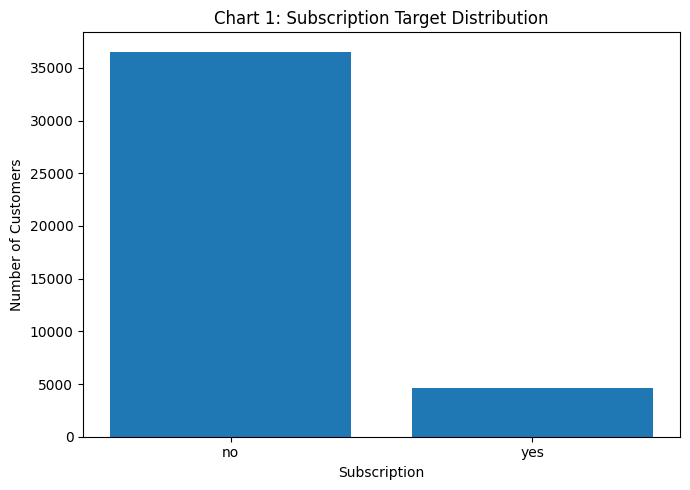

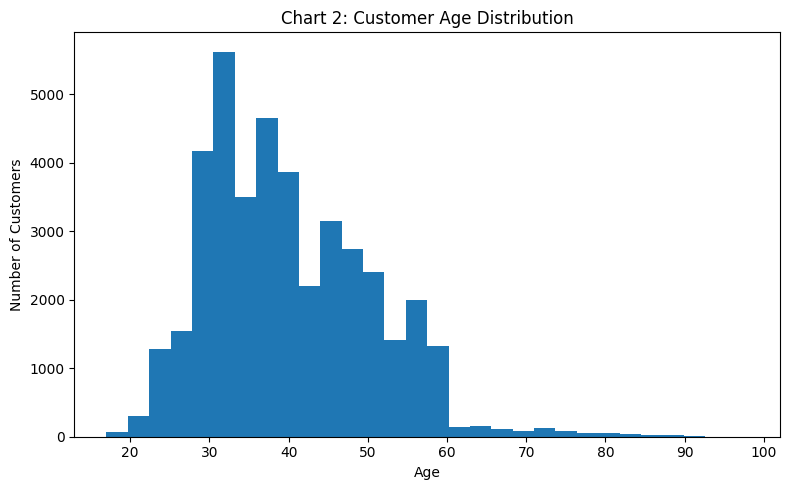

<Figure size 700x500 with 0 Axes>

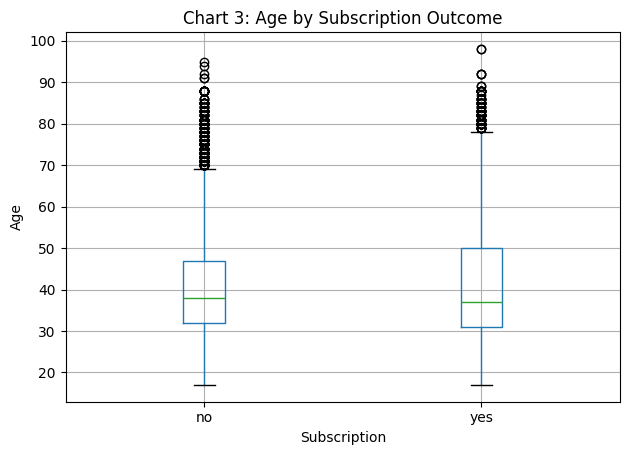

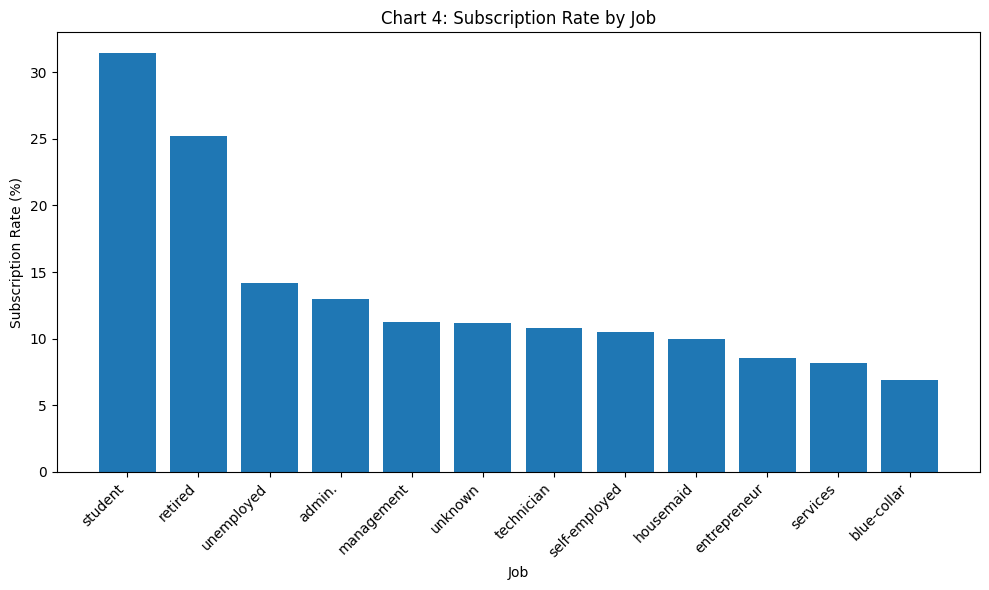

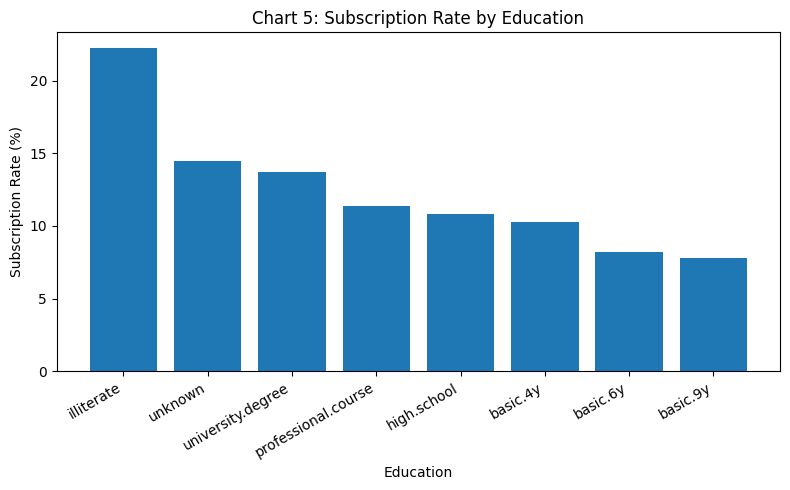

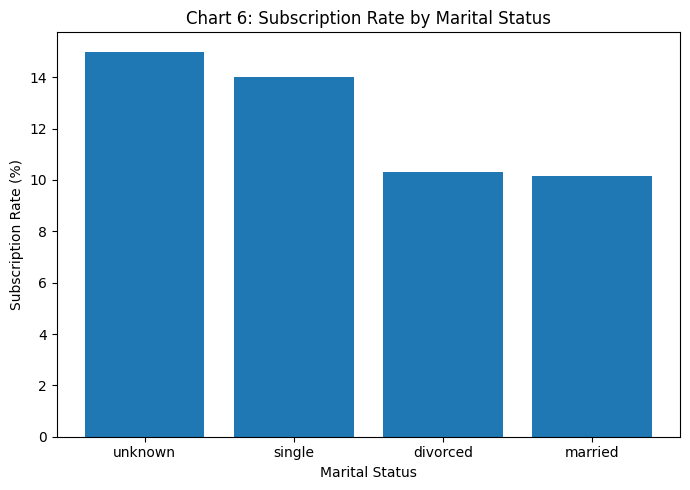

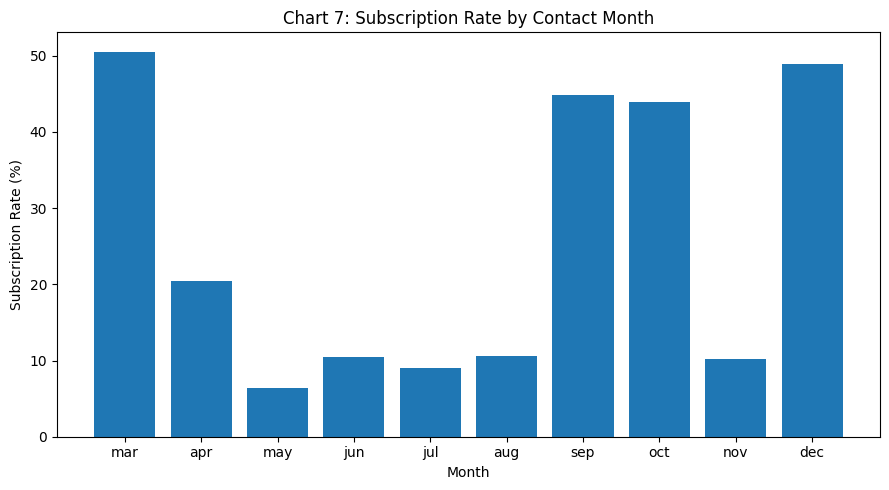

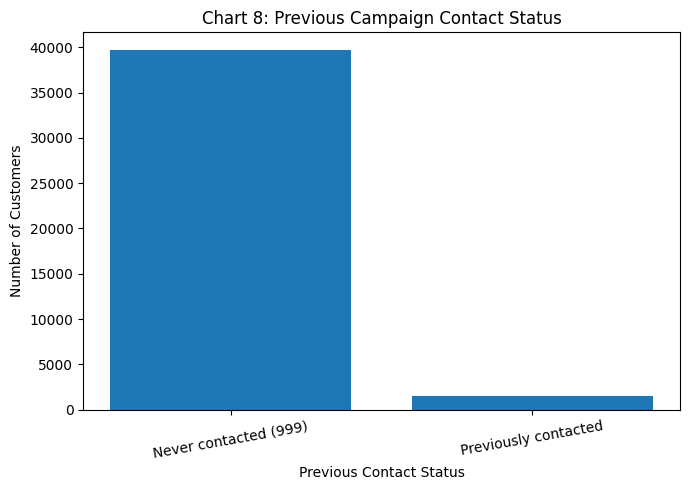

All 8 EDA charts generated and saved.
Five testable hypotheses saved.
Chart folder: ['chart_03_age_by_target.png', 'chart_08_pdays_status.png', 'chart_06_marital_subscription_rate.png', 'chart_04_job_subscription_rate.png', 'chart_02_age_distribution.png', 'chart_01_target_distribution.png', 'eda_hypotheses.csv', 'chart_07_month_subscription_rate.png', 'chart_05_education_subscription_rate.png']


In [28]:
import matplotlib.pyplot as plt
import os

# Create a folder for charts
os.makedirs("eda_charts", exist_ok=True)

# Use a copy for EDA
eda_df = df.copy()

# Convert target to readable labels for plotting
eda_df["subscription"] = eda_df["y"].map({
    "no": 0,
    "yes": 1
})

# ---------------------------------------
# CHART 1: Target distribution
# ---------------------------------------

target_counts = eda_df["y"].value_counts().reindex(
    ["no", "yes"], fill_value=0
)

plt.figure(figsize=(7, 5))
plt.bar(target_counts.index, target_counts.values)
plt.title("Chart 1: Subscription Target Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("eda_charts/chart_01_target_distribution.png")
plt.show()

# ---------------------------------------
# CHART 2: Customer age distribution
# ---------------------------------------

plt.figure(figsize=(8, 5))
plt.hist(eda_df["age"], bins=30)
plt.title("Chart 2: Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("eda_charts/chart_02_age_distribution.png")
plt.show()

# ---------------------------------------
# CHART 3: Age distribution by subscription
# ---------------------------------------

plt.figure(figsize=(7, 5))
eda_df.boxplot(column="age", by="y")
plt.title("Chart 3: Age by Subscription Outcome")
plt.suptitle("")
plt.xlabel("Subscription")
plt.ylabel("Age")
plt.tight_layout()
plt.savefig("eda_charts/chart_03_age_by_target.png")
plt.show()

# ---------------------------------------
# CHART 4: Subscription rate by job
# ---------------------------------------

job_rate = (
    eda_df.groupby("job", observed=False)["subscription"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 6))
plt.bar(job_rate.index, job_rate.values)
plt.title("Chart 4: Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("eda_charts/chart_04_job_subscription_rate.png")
plt.show()

# ---------------------------------------
# CHART 5: Subscription rate by education
# ---------------------------------------

education_rate = (
    eda_df.groupby("education", observed=False)["subscription"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(8, 5))
plt.bar(education_rate.index, education_rate.values)
plt.title("Chart 5: Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("eda_charts/chart_05_education_subscription_rate.png")
plt.show()

# ---------------------------------------
# CHART 6: Subscription rate by marital status
# ---------------------------------------

marital_rate = (
    eda_df.groupby("marital", observed=False)["subscription"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(7, 5))
plt.bar(marital_rate.index, marital_rate.values)
plt.title("Chart 6: Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("eda_charts/chart_06_marital_subscription_rate.png")
plt.show()

# ---------------------------------------
# CHART 7: Subscription rate by contact month
# ---------------------------------------

month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_rate = (
    eda_df.groupby("month")["subscription"]
    .mean()
    .reindex(month_order)
    .dropna() * 100
)

plt.figure(figsize=(9, 5))
plt.bar(month_rate.index, month_rate.values)
plt.title("Chart 7: Subscription Rate by Contact Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.savefig("eda_charts/chart_07_month_subscription_rate.png")
plt.show()

# ---------------------------------------
# CHART 8: pdays special-value distribution
# ---------------------------------------

pdays_groups = pd.Series({
    "Never contacted (999)": int((eda_df["pdays"] == 999).sum()),
    "Previously contacted": int((eda_df["pdays"] != 999).sum())
})

plt.figure(figsize=(7, 5))
plt.bar(pdays_groups.index, pdays_groups.values)
plt.title("Chart 8: Previous Campaign Contact Status")
plt.xlabel("Previous Contact Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("eda_charts/chart_08_pdays_status.png")
plt.show()

# ---------------------------------------
# Save five testable hypotheses
# ---------------------------------------

hypotheses = [
    {
        "id": "H1",
        "hypothesis": "Subscription rate may differ across job categories.",
        "investigation": "Compare subscription rates by job."
    },
    {
        "id": "H2",
        "hypothesis": "Subscription rate may differ across education levels.",
        "investigation": "Compare subscription rates by education."
    },
    {
        "id": "H3",
        "hypothesis": "Customer age may be associated with subscription outcome.",
        "investigation": "Compare age distributions for yes and no."
    },
    {
        "id": "H4",
        "hypothesis": "Subscription rate may vary by contact month.",
        "investigation": "Compare subscription rates across months."
    },
    {
        "id": "H5",
        "hypothesis": "Previous campaign contact history may be associated with subscription.",
        "investigation": "Compare outcomes for previously contacted and never-contacted customers."
    }
]

hypothesis_df = pd.DataFrame(hypotheses)

hypothesis_df.to_csv(
    "eda_charts/eda_hypotheses.csv",
    index=False
)

print("All 8 EDA charts generated and saved.")
print("Five testable hypotheses saved.")
print("Chart folder:", os.listdir("eda_charts"))

In [29]:
import numpy as np
import pandas as pd

# Work on copies so original data remains unchanged
X_A_engineered = X_A.copy()
X_B_engineered = X_B.copy()

# Create previously_contacted indicator
for dataset in [X_A_engineered, X_B_engineered]:

    dataset["previously_contacted"] = (
        dataset["pdays"] != 999
    ).astype(int)

    # Replace sentinel value with missing value
    dataset["pdays"] = dataset["pdays"].replace(
        999, np.nan
    )

print("Feature engineering completed!")

print("\nSet A shape:", X_A_engineered.shape)
print("Set B shape:", X_B_engineered.shape)

print("\nPreviously contacted distribution:")
print(
    X_A_engineered["previously_contacted"].value_counts()
)

print("\npdays missing values after sentinel conversion:")
print(X_A_engineered["pdays"].isna().sum())

Feature engineering completed!

Set A shape: (41188, 14)
Set B shape: (41188, 20)

Previously contacted distribution:
previously_contacted
0    39673
1     1515
Name: count, dtype: int64

pdays missing values after sentinel conversion:
39673


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X_A_engineered.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_A_engineered.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['age', 'pdays', 'previous', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Preprocessing pipeline created successfully!


In [31]:
from sklearn.linear_model import LogisticRegression

classification_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    ))
])

print("Complete classification pipeline created!")
print(classification_pipeline)

Complete classification pipeline created!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'pdays', 'previous',
                                                   'previously_contacted']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                

In [32]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
import pandas as pd

fold_results = []

for fold_number, (train_range, val_range) in enumerate(
    fold_ranges, start=1
):

    train_start, train_end = train_range
    val_start, val_end = val_range

    # Get chronological training and validation records
    X_fold_train = X_A_engineered.iloc[
        train_start:train_end
    ].copy()

    y_fold_train = y_train.iloc[
        train_start:train_end
    ].copy()

    X_fold_val = X_A_engineered.iloc[
        val_start:val_end
    ].copy()

    y_fold_val = y_train.iloc[
        val_start:val_end
    ].copy()

    # Create a fresh pipeline for every fold
    fold_model = clone(classification_pipeline)

    # Train
    fold_model.fit(X_fold_train, y_fold_train)

    # Predict probabilities
    probabilities = fold_model.predict_proba(
        X_fold_val
    )[:, 1]

    # Evaluate
    ap = average_precision_score(
        y_fold_val,
        probabilities
    )

    fold_results.append({
        "fold": fold_number,
        "training_records": len(X_fold_train),
        "validation_records": len(X_fold_val),
        "average_precision": ap
    })

    print(
        f"Fold {fold_number} | "
        f"Average Precision: {ap:.4f}"
    )

fold_results_df = pd.DataFrame(fold_results)

print("\nFold Results:")
display(fold_results_df)

print(
    "Mean Average Precision:",
    round(fold_results_df["average_precision"].mean(), 4)
)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Fold 1 | Average Precision: 0.0672


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Fold 2 | Average Precision: 0.0656
Fold 3 | Average Precision: 0.0502

Fold Results:


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,fold,training_records,validation_records,average_precision
0,1,10000,4904,0.067154
1,2,14904,4904,0.065611
2,3,19808,4904,0.050243


Mean Average Precision: 0.061


In [33]:
import json
import joblib

# Save the pipeline configuration
pipeline_information = {
    "project": "Bank Marketing - Campaign Intelligence",
    "feature_set": "Set A",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "engineered_features": [
        "previously_contacted",
        "pdays with 999 converted to missing"
    ],
    "preprocessing": {
        "numeric_imputer": "median",
        "numeric_scaler": "StandardScaler",
        "categorical_imputer": "most_frequent",
        "categorical_encoder": "OneHotEncoder",
        "handle_unknown": "ignore"
    },
    "validation_method": "3 forward chronological folds",
    "primary_metric": "Average Precision"
}

with open("phase5_pipeline_config.json", "w") as file:
    json.dump(pipeline_information, file, indent=4)

# Save fold results
fold_results_df.to_csv(
    "phase5_fold_results.csv",
    index=False
)

print("Phase 5 configuration and results saved!")

Phase 5 configuration and results saved!


In [34]:

# PHASE 6: BASELINE MODELS & MODEL COMPARISON

import time
import json
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# 1. Check required variables
required_variables = [
    "X_A_engineered", "y_train", "fold_ranges"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise ValueError(
        f"Missing variables: {missing_variables}. "
        "Please run the Phase 3 and Phase 5 cells first."
    )

# 2. Identify numeric and categorical columns
numeric_features = X_A_engineered.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_A_engineered.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# 3. Create preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 4. Define six models
models = {
    "Dummy Baseline": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=15,
        n_jobs=-1
    )
}

# 5. Evaluate all models on the same chronological folds
results = []

for model_name, model in models.items():

    print(f"\nEvaluating: {model_name}")

    for fold_number, (train_range, val_range) in enumerate(
        fold_ranges, start=1
    ):

        train_start, train_end = train_range
        val_start, val_end = val_range

        X_fold_train = X_A_engineered.iloc[
            train_start:train_end
        ].copy()

        y_fold_train = (
            df["y"].iloc[train_start:train_end] == "yes"
        ).astype(int)

        X_fold_val = X_A_engineered.iloc[
            val_start:val_end
        ].copy()

        y_fold_val = (
            df["y"].iloc[val_start:val_end] == "yes"
        ).astype(int)

        # Fresh preprocessing + model for every fold
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ])

        # Measure training time
        start_time = time.time()
        pipeline.fit(X_fold_train, y_fold_train)
        fit_seconds = time.time() - start_time

        # Measure prediction time
        start_time = time.time()
        probabilities = pipeline.predict_proba(X_fold_val)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)
        predict_seconds = time.time() - start_time

        # Evaluation metrics
        ap = average_precision_score(
            y_fold_val, probabilities
        )

        roc_auc = (
            roc_auc_score(y_fold_val, probabilities)
            if y_fold_val.nunique() == 2
            else np.nan
        )

        results.append({
            "model": model_name,
            "fold": fold_number,
            "average_precision": ap,
            "roc_auc": roc_auc,
            "precision_at_0_5": precision_score(
                y_fold_val, predictions, zero_division=0
            ),
            "recall_at_0_5": recall_score(
                y_fold_val, predictions, zero_division=0
            ),
            "f1_at_0_5": f1_score(
                y_fold_val, predictions, zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_fold_val, predictions
            ),
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds
        })

        print(
            f"  Fold {fold_number}: "
            f"AP={ap:.4f}, "
            f"ROC-AUC={roc_auc:.4f}, "
            f"Fit={fit_seconds:.2f}s"
        )

# 6. Create detailed results table
fold_results_df = pd.DataFrame(results)

# 7. Summarize mean and standard deviation across folds
summary_df = (
    fold_results_df
    .groupby("model")
    .agg({
        "average_precision": ["mean", "std"],
        "roc_auc": ["mean", "std"],
        "precision_at_0_5": "mean",
        "recall_at_0_5": "mean",
        "f1_at_0_5": "mean",
        "balanced_accuracy": "mean",
        "fit_seconds": "mean",
        "predict_seconds": "mean"
    })
)

summary_df.columns = [
    "_".join(col).strip("_")
    for col in summary_df.columns
]

summary_df = summary_df.sort_values(
    "average_precision_mean",
    ascending=False
)

# 8. Save experiment results
import os
os.makedirs("results", exist_ok=True)

fold_results_df.to_csv(
    "results/phase6_fold_results.csv",
    index=False
)

summary_df.to_csv(
    "results/phase6_model_comparison.csv"
)

print("\n========== MODEL COMPARISON ==========")
display(summary_df.round(4))

print("\nSaved:")
print("results/phase6_fold_results.csv")
print("results/phase6_model_comparison.csv")



Evaluating: Dummy Baseline
  Fold 1: AP=0.0544, ROC-AUC=0.5000, Fit=0.05s


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fold 2: AP=0.0606, ROC-AUC=0.5000, Fit=0.07s


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fold 3: AP=0.0591, ROC-AUC=0.5000, Fit=0.16s

Evaluating: Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


... (25 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['pdays']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


  Fold 3: AP=0.0538, ROC-AUC=0.4507, Fit=0.31s

========== MODEL COMPARISON ==========


,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,precision_at_0_5_mean,recall_at_0_5_mean,f1_at_0_5_mean,balanced_accuracy_mean,fit_seconds_mean,predict_seconds_mean
model,,,,,,,,,,
Logistic Regression,0.0610,0.0093,0.5009,0.0805,0.0000,0.0000,0.000,0.5000,0.2890,0.0905
Dummy Baseline,0.0580,0.0032,0.5000,0.0000,0.0000,0.0000,0.000,0.5000,0.0937,0.0292
KNN,0.0557,0.0022,0.4751,0.0244,0.0000,0.0000,0.000,0.5000,0.2321,1.5753
Decision Tree,0.0553,0.0070,0.4731,0.0643,0.0101,0.0011,0.002,0.4976,0.1719,0.0528
Random Forest,0.0551,0.0047,0.4670,0.0464,0.0000,0.0000,0.000,0.5000,1.4450,0.1517
Hist Gradient Boosting,0.0536,0.0092,0.4610,0.0560,0.0000,0.0000,0.000,0.5000,1.5766,0.2305



Saved:
results/phase6_fold_results.csv
results/phase6_model_comparison.csv


In [35]:

# FIX: PDAYS FEATURE

# Start again from original Set A
X_A_engineered = X_A.copy()

# Create a flag: 1 = contacted before, 0 = never contacted
X_A_engineered["previously_contacted"] = (
    X_A_engineered["pdays"] != 999
).astype(int)

# Remove pdays because 999 becomes entirely missing
# in some early chronological training folds
X_A_engineered = X_A_engineered.drop(columns=["pdays"])

# Safety checks
assert "pdays" not in X_A_engineered.columns
assert "previously_contacted" in X_A_engineered.columns
assert "duration" not in X_A_engineered.columns

print("Feature correction successful!")
print("Updated feature shape:", X_A_engineered.shape)
print("\nPreviously contacted distribution:")
print(X_A_engineered["previously_contacted"].value_counts())


Feature correction successful!
Updated feature shape: (41188, 13)

Previously contacted distribution:
previously_contacted
0    39673
1     1515
Name: count, dtype: int64


In [36]:

# PHASE 7: CLASS IMBALANCE HANDLING

!pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import time
import json
import os

from sklearn.base import clone
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Check corrected features and chronological folds
assert "pdays" not in X_A_engineered.columns
assert "previously_contacted" in X_A_engineered.columns

print("Imbalanced-learn installed.")
print("Features:", X_A_engineered.shape[1])
print("Chronological folds:", len(fold_ranges))

print("\nTraining class distribution:")
print(y_train.value_counts())


Imbalanced-learn installed.
Features: 13
Chronological folds: 3

Training class distribution:
y
0    23524
1     1188
Name: count, dtype: int64


In [37]:

# PHASE 7: BALANCING EXPERIMENTS

experiment_models = {
    "Logistic Regression": {
        "none": LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        "class_weight": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ),
        "oversampling": LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    },

    "Random Forest": {
        "none": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=42,
            n_jobs=-1
        ),
        "class_weight": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "oversampling": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=42,
            n_jobs=-1
        )
    }
}

experiment_results = []

for model_name, strategies in experiment_models.items():

    for strategy_name, estimator in strategies.items():

        for fold_number, (train_range, val_range) in enumerate(
            fold_ranges, start=1
        ):

            train_start, train_end = train_range
            val_start, val_end = val_range

            X_tr = X_A_engineered.iloc[
                train_start:train_end
            ].copy()

            y_tr = (
                df["y"].iloc[train_start:train_end] == "yes"
            ).astype(int)

            X_val = X_A_engineered.iloc[
                val_start:val_end
            ].copy()

            y_val = (
                df["y"].iloc[val_start:val_end] == "yes"
            ).astype(int)

            steps = [("preprocessor", clone(preprocessor))]

            if strategy_name == "oversampling":
                steps.append((
                    "oversampler",
                    RandomOverSampler(random_state=42)
                ))

            steps.append(("model", clone(estimator)))

            pipeline = ImbPipeline(steps)

            start = time.time()
            pipeline.fit(X_tr, y_tr)
            fit_seconds = time.time() - start

            probabilities = pipeline.predict_proba(X_val)[:, 1]

            ap = average_precision_score(
                y_val, probabilities
            )

            experiment_results.append({
                "model": model_name,
                "strategy": strategy_name,
                "fold": fold_number,
                "average_precision": ap,
                "fit_seconds": fit_seconds,
                "training_positive_rate": y_tr.mean(),
                "validation_positive_rate": y_val.mean()
            })

            print(
                f"{model_name} | {strategy_name} | "
                f"Fold {fold_number} | AP={ap:.4f}"
            )

# Detailed experiment results
imbalance_results_df = pd.DataFrame(experiment_results)

# Aggregate results
imbalance_summary_df = (
    imbalance_results_df
    .groupby(["model", "strategy"])
    .agg(
        AP_mean=("average_precision", "mean"),
        AP_std=("average_precision", "std"),
        fit_seconds_mean=("fit_seconds", "mean")
    )
    .reset_index()
    .sort_values("AP_mean", ascending=False)
)

os.makedirs("results", exist_ok=True)

imbalance_results_df.to_csv(
    "results/phase7_imbalance_fold_results.csv",
    index=False
)

imbalance_summary_df.to_csv(
    "results/phase7_imbalance_comparison.csv",
    index=False
)

print("\n========== IMBALANCE COMPARISON ==========")
display(imbalance_summary_df.round(4))


ValueError: A given column is not a column of the dataframe

In [38]:

# PHASE 7: CLASS IMBALANCE HANDLING

!pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import time
import json
import os

from sklearn.base import clone
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Check corrected features and chronological folds
assert "pdays" not in X_A_engineered.columns
assert "previously_contacted" in X_A_engineered.columns

print("Imbalanced-learn installed.")
print("Features:", X_A_engineered.shape[1])
print("Chronological folds:", len(fold_ranges))

print("\nTraining class distribution:")
print(y_train.value_counts())


Imbalanced-learn installed.
Features: 13
Chronological folds: 3

Training class distribution:
y
0    23524
1     1188
Name: count, dtype: int64


In [39]:

# PHASE 7: BALANCING EXPERIMENTS

experiment_models = {
    "Logistic Regression": {
        "none": LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        "class_weight": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ),
        "oversampling": LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    },

    "Random Forest": {
        "none": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=42,
            n_jobs=-1
        ),
        "class_weight": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "oversampling": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=42,
            n_jobs=-1
        )
    }
}

experiment_results = []

for model_name, strategies in experiment_models.items():

    for strategy_name, estimator in strategies.items():

        for fold_number, (train_range, val_range) in enumerate(
            fold_ranges, start=1
        ):

            train_start, train_end = train_range
            val_start, val_end = val_range

            X_tr = X_A_engineered.iloc[
                train_start:train_end
            ].copy()

            y_tr = (
                df["y"].iloc[train_start:train_end] == "yes"
            ).astype(int)

            X_val = X_A_engineered.iloc[
                val_start:val_end
            ].copy()

            y_val = (
                df["y"].iloc[val_start:val_end] == "yes"
            ).astype(int)

            steps = [("preprocessor", clone(preprocessor))]

            if strategy_name == "oversampling":
                steps.append((
                    "oversampler",
                    RandomOverSampler(random_state=42)
                ))

            steps.append(("model", clone(estimator)))

            pipeline = ImbPipeline(steps)

            start = time.time()
            pipeline.fit(X_tr, y_tr)
            fit_seconds = time.time() - start

            probabilities = pipeline.predict_proba(X_val)[:, 1]

            ap = average_precision_score(
                y_val, probabilities
            )

            experiment_results.append({
                "model": model_name,
                "strategy": strategy_name,
                "fold": fold_number,
                "average_precision": ap,
                "fit_seconds": fit_seconds,
                "training_positive_rate": y_tr.mean(),
                "validation_positive_rate": y_val.mean()
            })

            print(
                f"{model_name} | {strategy_name} | "
                f"Fold {fold_number} | AP={ap:.4f}"
            )

# Detailed experiment results
imbalance_results_df = pd.DataFrame(experiment_results)

# Aggregate results
imbalance_summary_df = (
    imbalance_results_df
    .groupby(["model", "strategy"])
    .agg(
        AP_mean=("average_precision", "mean"),
        AP_std=("average_precision", "std"),
        fit_seconds_mean=("fit_seconds", "mean")
    )
    .reset_index()
    .sort_values("AP_mean", ascending=False)
)

os.makedirs("results", exist_ok=True)

imbalance_results_df.to_csv(
    "results/phase7_imbalance_fold_results.csv",
    index=False
)

imbalance_summary_df.to_csv(
    "results/phase7_imbalance_comparison.csv",
    index=False
)

print("\n========== IMBALANCE COMPARISON ==========")
display(imbalance_summary_df.round(4))


ValueError: A given column is not a column of the dataframe

In [40]:

# FIX PHASE 7: REBUILD PREPROCESSOR

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Detect columns from updated feature dataset
numeric_features = X_A_engineered.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_A_engineered.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Rebuild preprocessor using updated columns
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Verify columns
all_preprocessor_columns = (
    numeric_features + categorical_features
)

assert set(all_preprocessor_columns) == set(
    X_A_engineered.columns
)

assert "pdays" not in all_preprocessor_columns

print("Preprocessor successfully updated!")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Total features:", len(all_preprocessor_columns))


Preprocessor successfully updated!
Numeric features: ['age', 'previous', 'previously_contacted']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Total features: 13


In [41]:

# PHASE 7: SELECT TOP 2 CANDIDATES

assert "imbalance_summary_df" in globals(), (
    "Please run the Phase 7 imbalance comparison first."
)

top_candidates = (
    imbalance_summary_df
    .sort_values("AP_mean", ascending=False)
    .head(2)
    .reset_index(drop=True)
)

print("Selected candidates for tuning:")
display(top_candidates)

candidate_pairs = list(
    zip(top_candidates["model"], top_candidates["strategy"])
)

print("\nCandidate combinations:")
for model_name, strategy in candidate_pairs:
    print(f"- {model_name} | {strategy}")


AssertionError: Please run the Phase 7 imbalance comparison first.

In [42]:

# PHASE 7: BOUNDED HYPERPARAMETER TUNING

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import time
import pandas as pd
import os

# Ensure preprocessor is built correctly without 'pdays'
numeric_features = X_A_engineered.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_A_engineered.select_dtypes(include=["object", "category", "string"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fallback definition for candidate_pairs if previous cells were not run
if "candidate_pairs" not in globals():
    print("candidate_pairs not found in memory; using default candidates for tuning.")
    candidate_pairs = [
        ("Logistic Regression", "oversampling"),
        ("Random Forest", "oversampling")
    ]

# Four configurations per candidate
tuning_configs = {
    "Logistic Regression": [
        {"C": 0.01},
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0}
    ],
    "Random Forest": [
        {"n_estimators": 100, "max_depth": 3, "min_samples_leaf": 5},
        {"n_estimators": 100, "max_depth": 5, "min_samples_leaf": 5},
        {"n_estimators": 200, "max_depth": 5, "min_samples_leaf": 10},
        {"n_estimators": 200, "max_depth": 8, "min_samples_leaf": 10}
    ]
}

tuning_results = []

for model_name, strategy in candidate_pairs:

    print(f"\nTuning: {model_name} | {strategy}")

    for config_number, config in enumerate(
        tuning_configs[model_name], start=1
    ):

        fold_scores = []
        fold_times = []

        for fold_number, (train_range, val_range) in enumerate(
            fold_ranges, start=1
        ):

            train_start, train_end = train_range
            val_start, val_end = val_range

            X_tr = X_A_engineered.iloc[
                train_start:train_end
            ].copy()

            y_tr = (
                df["y"].iloc[train_start:train_end] == "yes"
            ).astype(int)

            X_val = X_A_engineered.iloc[
                val_start:val_end
            ].copy()

            y_val = (
                df["y"].iloc[val_start:val_end] == "yes"
            ).astype(int)

            # Build model with current configuration
            if model_name == "Logistic Regression":
                estimator = LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                    **config
                )
            else:
                estimator = RandomForestClassifier(
                    random_state=42,
                    n_jobs=-1,
                    **config
                )

            steps = [("preprocessor", clone(preprocessor))]

            if strategy == "oversampling":
                steps.append((
                    "oversampler",
                    RandomOverSampler(random_state=42)
                ))

            steps.append(("model", estimator))

            pipeline = ImbPipeline(steps)

            start = time.time()
            pipeline.fit(X_tr, y_tr)
            elapsed = time.time() - start

            probabilities = pipeline.predict_proba(X_val)[:, 1]

            score = average_precision_score(
                y_val, probabilities
            )

            fold_scores.append(score)
            fold_times.append(elapsed)

        tuning_results.append({
            "model": model_name,
            "strategy": strategy,
            "config_number": config_number,
            "parameters": str(config),
            "AP_mean": sum(fold_scores) / len(fold_scores),
            "AP_std": pd.Series(fold_scores).std(),
            "fit_seconds_mean": sum(fold_times) / len(fold_times)
        })

        print(
            f"Config {config_number}: "
            f"Mean AP = {sum(fold_scores) / len(fold_scores):.4f}"
        )

# Save tuning results
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    "AP_mean", ascending=False
)

os.makedirs("results", exist_ok=True)

tuning_results_df.to_csv(
    "results/phase7_hyperparameter_tuning.csv",
    index=False
)

print("\n========== TUNING RESULTS ==========")
display(tuning_results_df.round(4))

best_configuration = tuning_results_df.iloc[0]

print("\nBEST CONFIGURATION:")
print(best_configuration.to_dict())


NameError: name 'candidate_pairs' is not defined

In [43]:

# PHASE 7: COMPLETE RECOVERY + CANDIDATE SELECTION

import numpy as np
import pandas as pd
import time
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# 1. Rebuild preprocessor from current features
numeric_features = X_A_engineered.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_A_engineered.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), categorical_features)
])

assert "pdays" not in numeric_features + categorical_features

# 2. Define experiment combinations
experiment_models = {
    "Logistic Regression": {
        "none": LogisticRegression(max_iter=1000, random_state=42),
        "class_weight": LogisticRegression(
            max_iter=1000, class_weight="balanced", random_state=42
        ),
        "oversampling": LogisticRegression(
            max_iter=1000, random_state=42
        )
    },
    "Random Forest": {
        "none": RandomForestClassifier(
            n_estimators=100, max_depth=5,
            random_state=42, n_jobs=-1
        ),
        "class_weight": RandomForestClassifier(
            n_estimators=100, max_depth=5,
            class_weight="balanced",
            random_state=42, n_jobs=-1
        ),
        "oversampling": RandomForestClassifier(
            n_estimators=100, max_depth=5,
            random_state=42, n_jobs=-1
        )
    }
}

results = []

# 3. Run all 18 experiments
for model_name, strategies in experiment_models.items():

    for strategy, estimator in strategies.items():

        for fold_number, (train_range, val_range) in enumerate(
            fold_ranges, start=1
        ):

            a, b = train_range
            c, d = val_range

            X_tr = X_A_engineered.iloc[a:b].copy()
            X_val = X_A_engineered.iloc[c:d].copy()

            y_tr = (df["y"].iloc[a:b] == "yes").astype(int)
            y_val = (df["y"].iloc[c:d] == "yes").astype(int)

            steps = [("preprocessor", clone(preprocessor))]

            if strategy == "oversampling":
                steps.append((
                    "oversampler",
                    RandomOverSampler(random_state=42)
                ))

            steps.append(("model", clone(estimator)))

            pipeline = ImbPipeline(steps)

            start = time.time()
            pipeline.fit(X_tr, y_tr)
            fit_time = time.time() - start

            probabilities = pipeline.predict_proba(X_val)[:, 1]

            ap = average_precision_score(y_val, probabilities)

            results.append({
                "model": model_name,
                "strategy": strategy,
                "fold": fold_number,
                "average_precision": ap,
                "fit_seconds": fit_time
            })

            print(
                f"{model_name} | {strategy} | "
                f"Fold {fold_number} | AP={ap:.4f}"
            )

# 4. Summarize results
imbalance_results_df = pd.DataFrame(results)

imbalance_summary_df = (
    imbalance_results_df
    .groupby(["model", "strategy"])
    .agg(
        AP_mean=("average_precision", "mean"),
        AP_std=("average_precision", "std"),
        fit_seconds_mean=("fit_seconds", "mean")
    )
    .reset_index()
    .sort_values("AP_mean", ascending=False)
)

# 5. Select actual top two combinations
top_candidates = imbalance_summary_df.head(2).copy()

candidate_pairs = list(zip(
    top_candidates["model"],
    top_candidates["strategy"]
))

# 6. Save evidence
os.makedirs("results", exist_ok=True)

imbalance_results_df.to_csv(
    "results/phase7_imbalance_fold_results.csv",
    index=False
)

imbalance_summary_df.to_csv(
    "results/phase7_imbalance_comparison.csv",
    index=False
)

top_candidates.to_csv(
    "results/phase7_selected_candidates.csv",
    index=False
)

print("\n========== IMBALANCE COMPARISON ==========")
display(imbalance_summary_df.round(4))

print("\n========== SELECTED CANDIDATES ==========")
display(top_candidates)

print("\nCandidate pairs:", candidate_pairs)


Logistic Regression | none | Fold 1 | AP=0.0672
Logistic Regression | none | Fold 2 | AP=0.0656
Logistic Regression | none | Fold 3 | AP=0.0502
Logistic Regression | class_weight | Fold 1 | AP=0.0518
Logistic Regression | class_weight | Fold 2 | AP=0.0668
Logistic Regression | class_weight | Fold 3 | AP=0.0537
Logistic Regression | oversampling | Fold 1 | AP=0.0524
Logistic Regression | oversampling | Fold 2 | AP=0.0652
Logistic Regression | oversampling | Fold 3 | AP=0.0548
Random Forest | none | Fold 1 | AP=0.0522
Random Forest | none | Fold 2 | AP=0.0605
Random Forest | none | Fold 3 | AP=0.0527
Random Forest | class_weight | Fold 1 | AP=0.0541
Random Forest | class_weight | Fold 2 | AP=0.0619
Random Forest | class_weight | Fold 3 | AP=0.0510
Random Forest | oversampling | Fold 1 | AP=0.0520
Random Forest | oversampling | Fold 2 | AP=0.0668
Random Forest | oversampling | Fold 3 | AP=0.0479

========== IMBALANCE COMPARISON ==========


,model,strategy,AP_mean,AP_std,fit_seconds_mean
1,Logistic Regression,none,0.0610,0.0093,0.3362
2,Logistic Regression,oversampling,0.0575,0.0068,0.6825
0,Logistic Regression,class_weight,0.0574,0.0082,0.5051
3,Random Forest,class_weight,0.0556,0.0056,1.5594
5,Random Forest,oversampling,0.0556,0.0100,1.1044
4,Random Forest,none,0.0551,0.0047,1.1686



========== SELECTED CANDIDATES ==========


,model,strategy,AP_mean,AP_std,fit_seconds_mean
1,Logistic Regression,none,0.061002,0.009350,0.336202
2,Logistic Regression,oversampling,0.057457,0.006829,0.682541



Candidate pairs: [('Logistic Regression', 'none'), ('Logistic Regression', 'oversampling')]


In [44]:
from sklearn.metrics import average_precision_score

In [45]:

# PHASE 7 — HYPERPARAMETER TUNING
# 2 selected candidates × 12 configurations × 3 chronological folds = 72 fits

import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# 1. Confirm selected candidates exist
candidate_pairs = [
    ("Logistic Regression", "none"),
    ("Logistic Regression", "oversampling")
]

# 2. Define 12 configurations
configurations = [
    {"C": c, "fit_intercept": intercept}
    for c in [0.001, 0.01, 0.1, 1, 10, 100]
    for intercept in [True, False]
]

# 3. Use the three predefined chronological folds
fold_ranges = [
    ((0, 10000), (10000, 14904)),
    ((0, 14904), (14904, 19808)),
    ((0, 19808), (19808, 24712))
]

tuning_results = []

for model_name, strategy in candidate_pairs:

    for config_id, config in enumerate(configurations, start=1):

        for fold_number, (train_range, val_range) in enumerate(fold_ranges, start=1):

            train_start, train_end = train_range
            val_start, val_end = val_range

            X_fold_train = X_A_engineered.iloc[train_start:train_end]
            y_fold_train = y_train.iloc[train_start:train_end]

            X_fold_val = X_A_engineered.iloc[val_start:val_end]
            y_fold_val = y_train.iloc[val_start:val_end]

            # Fresh model for every fold
            logistic_model = LogisticRegression(
                C=config["C"],
                fit_intercept=config["fit_intercept"],
                solver="lbfgs",
                max_iter=2000,
                random_state=42
            )

            if strategy == "oversampling":
                model_pipeline = ImbPipeline([
                    ("preprocessor", clone(preprocessor)),
                    ("sampler", RandomOverSampler(random_state=42)),
                    ("model", logistic_model)
                ])
            else:
                model_pipeline = SklearnPipeline([
                    ("preprocessor", clone(preprocessor)),
                    ("model", logistic_model)
                ])

            start_time = time.time()
            model_pipeline.fit(X_fold_train, y_fold_train)
            fit_seconds = time.time() - start_time

            probabilities = model_pipeline.predict_proba(X_fold_val)[:, 1]

            ap = average_precision_score(y_fold_val, probabilities)

            tuning_results.append({
                "model": model_name,
                "strategy": strategy,
                "config_id": config_id,
                "C": config["C"],
                "fit_intercept": config["fit_intercept"],
                "fold": fold_number,
                "average_precision": ap,
                "fit_seconds": fit_seconds
            })

            print(
                f"{strategy} | Config {config_id}/12 | "
                f"Fold {fold_number}/3 | AP={ap:.4f}"
            )

# 4. Save fold-level results
tuning_df = pd.DataFrame(tuning_results)

# 5. Compare configurations using mean AP across all 3 folds
tuning_summary = (
    tuning_df
    .groupby(["model", "strategy", "config_id", "C", "fit_intercept"])
    .agg(
        AP_mean=("average_precision", "mean"),
        AP_std=("average_precision", "std"),
        fit_seconds_mean=("fit_seconds", "mean")
    )
    .reset_index()
    .sort_values("AP_mean", ascending=False)
)

# 6. Save results
import os
os.makedirs("results", exist_ok=True)

tuning_df.to_csv(
    "results/phase7_tuning_fold_results.csv", index=False
)

tuning_summary.to_csv(
    "results/phase7_tuning_comparison.csv", index=False
)

print("\n========== TOP 10 TUNING CONFIGURATIONS ==========")
display(tuning_summary.head(10))

print("\nTotal model fits:", len(tuning_df))
print("Expected model fits: 72")
print("\nSaved tuning results successfully.")


none | Config 1/12 | Fold 1/3 | AP=0.0521
none | Config 1/12 | Fold 2/3 | AP=0.0712
none | Config 1/12 | Fold 3/3 | AP=0.0486
none | Config 2/12 | Fold 1/3 | AP=0.0651
none | Config 2/12 | Fold 2/3 | AP=0.0647
none | Config 2/12 | Fold 3/3 | AP=0.0502
none | Config 3/12 | Fold 1/3 | AP=0.0506
none | Config 3/12 | Fold 2/3 | AP=0.0749
none | Config 3/12 | Fold 3/3 | AP=0.0494
none | Config 4/12 | Fold 1/3 | AP=0.0672
none | Config 4/12 | Fold 2/3 | AP=0.0693
none | Config 4/12 | Fold 3/3 | AP=0.0481
none | Config 5/12 | Fold 1/3 | AP=0.0519
none | Config 5/12 | Fold 2/3 | AP=0.0684
none | Config 5/12 | Fold 3/3 | AP=0.0519
none | Config 6/12 | Fold 1/3 | AP=0.0684
none | Config 6/12 | Fold 2/3 | AP=0.0670
none | Config 6/12 | Fold 3/3 | AP=0.0501
none | Config 7/12 | Fold 1/3 | AP=0.0672
none | Config 7/12 | Fold 2/3 | AP=0.0656
none | Config 7/12 | Fold 3/3 | AP=0.0502
none | Config 8/12 | Fold 1/3 | AP=0.0684
none | Config 8/12 | Fold 2/3 | AP=0.0657
none | Config 8/12 | Fold 3/3 | AP

,model,strategy,config_id,C,fit_intercept,AP_mean,AP_std,fit_seconds_mean
5,Logistic Regression,none,6,0.100,False,0.061831,0.010193,0.375975
7,Logistic Regression,none,8,1.000,False,0.061647,0.009449,0.309318
3,Logistic Regression,none,4,0.010,False,0.061515,0.011665,0.247281
11,Logistic Regression,none,12,100.000,False,0.061493,0.009361,0.667844
9,Logistic Regression,none,10,10.000,False,0.061361,0.009222,0.322971
10,Logistic Regression,none,11,100.000,True,0.061047,0.009407,0.467924
8,Logistic Regression,none,9,10.000,True,0.061034,0.009402,0.346813
6,Logistic Regression,none,7,1.000,True,0.061002,0.009350,0.332574
1,Logistic Regression,none,2,0.001,False,0.060011,0.008467,0.401005
2,Logistic Regression,none,3,0.010,True,0.058317,0.014377,0.382700



Total model fits: 72
Expected model fits: 72

Saved tuning results successfully.


In [46]:

import os
import json

os.makedirs("results", exist_ok=True)

best_config = tuning_summary.iloc[0]

phase7_report = {
    "phase": "Phase 7 - Imbalance Handling and Hyperparameter Tuning",
    "selected_model": str(best_config["model"]),
    "selected_strategy": str(best_config["strategy"]),
    "best_config_id": int(best_config["config_id"]),
    "C": float(best_config["C"]),
    "fit_intercept": bool(best_config["fit_intercept"]),
    "mean_average_precision": float(best_config["AP_mean"]),
    "ap_standard_deviation": float(best_config["AP_std"]),
    "mean_fit_seconds": float(best_config["fit_seconds_mean"]),
    "total_tuning_fits": int(len(tuning_df)),
    "selection_reason": (
        "Highest mean Average Precision across three chronological folds. "
        "Oversampling and class weighting did not improve the baseline strategy."
    ),
    "limitations": [
        "Average Precision remains low.",
        "Chronological target prevalence changes substantially.",
        "Results are validation evidence, not proof of deployment readiness."
    ]
}

with open("results/phase7_final_report.json", "w") as f:
    json.dump(phase7_report, f, indent=4)

print("Phase 7 report saved successfully!")
print(json.dumps(phase7_report, indent=4))


Phase 7 report saved successfully!
{
    "phase": "Phase 7 - Imbalance Handling and Hyperparameter Tuning",
    "selected_model": "Logistic Regression",
    "selected_strategy": "none",
    "best_config_id": 6,
    "C": 0.1,
    "fit_intercept": false,
    "mean_average_precision": 0.06183084576890085,
    "ap_standard_deviation": 0.010193168763642929,
    "mean_fit_seconds": 0.37597497304280597,
    "total_tuning_fits": 72,
    "selection_reason": "Highest mean Average Precision across three chronological folds. Oversampling and class weighting did not improve the baseline strategy.",
    "limitations": [
        "Average Precision remains low.",
        "Chronological target prevalence changes substantially.",
        "Results are validation evidence, not proof of deployment readiness."
    ]
}


In [47]:

# PHASE 8 — CALIBRATION & EVALUATION

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)
from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("evaluation_plots", exist_ok=True)

# STEP 1: Train the selected base model on training data
base_model = SklearnPipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(
        C=0.1,
        fit_intercept=False,
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    ))
])

base_model.fit(X_train, y_train)

print("Base model trained successfully!")

# STEP 2: Calibrate using calibration data only
# FrozenEstimator keeps the already-trained model fixed.
try:
    from sklearn.frozen import FrozenEstimator

    calibrated_model = CalibratedClassifierCV(
        estimator=FrozenEstimator(base_model),
        method="sigmoid"
    )

except ImportError:
    # Compatibility with older scikit-learn versions
    calibrated_model = CalibratedClassifierCV(
        estimator=base_model,
        method="sigmoid",
        cv="prefit"
    )

calibrated_model.fit(X_calibration, y_calibration)

print("Probability calibration completed!")

# STEP 3: Predict on policy validation data
probabilities = calibrated_model.predict_proba(
    X_policy_validation
)[:, 1]

predictions = (probabilities >= 0.5).astype(int)

# STEP 4: Calculate evaluation metrics
metrics = {
    "average_precision": average_precision_score(
        y_policy_validation, probabilities
    ),
    "roc_auc": roc_auc_score(
        y_policy_validation, probabilities
    ),
    "precision_at_0.5": precision_score(
        y_policy_validation, predictions, zero_division=0
    ),
    "recall_at_0.5": recall_score(
        y_policy_validation, predictions, zero_division=0
    ),
    "f1_at_0.5": f1_score(
        y_policy_validation, predictions, zero_division=0
    ),
    "balanced_accuracy_at_0.5": balanced_accuracy_score(
        y_policy_validation, predictions
    ),
    "brier_score": brier_score_loss(
        y_policy_validation, probabilities
    ),
    "log_loss": log_loss(
        y_policy_validation, probabilities,
        labels=[0, 1]
    )
}

print("\n========== PHASE 8 EVALUATION ==========")

for metric_name, metric_value in metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

print(
    "\nPolicy validation positive rate:",
    round(float(y_policy_validation.mean()), 4)
)

print(
    "Mean predicted probability:",
    round(float(probabilities.mean()), 4)
)

# STEP 5: Confusion matrix
cm = confusion_matrix(y_policy_validation, predictions)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_policy_validation,
    predictions,
    zero_division=0
))

# STEP 6: Precision-Recall curve
precision_values, recall_values, _ = precision_recall_curve(
    y_policy_validation, probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(recall_values, precision_values)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.savefig("evaluation_plots/precision_recall_curve.png")
plt.show()

# STEP 7: ROC curve
fpr, tpr, _ = roc_curve(
    y_policy_validation, probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig("evaluation_plots/roc_curve.png")
plt.show()

# STEP 8: Calibration / Reliability curve
actual_fraction, predicted_fraction = calibration_curve(
    y_policy_validation,
    probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(
    predicted_fraction,
    actual_fraction,
    marker="o",
    label="Calibrated model"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Positive Fraction")
plt.title("Probability Calibration Curve")
plt.legend()
plt.tight_layout()
plt.savefig("evaluation_plots/calibration_curve.png")
plt.show()

# STEP 9: Save evaluation results
with open("results/phase8_metrics.json", "w") as f:
    json.dump(
        {key: float(value) for key, value in metrics.items()},
        f,
        indent=4
    )

joblib.dump(
    calibrated_model,
    "models/calibrated_logistic_regression.joblib"
)

validation_predictions = pd.DataFrame({
    "actual": y_policy_validation.to_numpy(),
    "predicted_probability": probabilities,
    "predicted_class_at_0.5": predictions
})

validation_predictions.to_csv(
    "results/phase8_policy_validation_predictions.csv",
    index=False
)

print("\nPhase 8 outputs saved successfully!")
print("Metrics: results/phase8_metrics.json")
print("Model: models/calibrated_logistic_regression.joblib")
print("Predictions: results/phase8_policy_validation_predictions.csv")


ValueError: A given column is not a column of the dataframe

In [48]:

# PHASE 8 — FIX FEATURE MISMATCH AND REBUILD PREPROCESSOR

import numpy as np
import pandas as pd
import joblib
import os

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# STEP 1: Create consistent features for all four datasets

def prepare_features(data):
    X = data[set_a_features].copy()

    # Convert pdays sentinel into a useful binary feature
    X["previously_contacted"] = (
        X["pdays"] != 999
    ).astype(int)

    # Remove original pdays column
    X = X.drop(columns=["pdays"])

    return X


X_train = prepare_features(train_df)
X_calibration = prepare_features(calibration_df)
X_policy_validation = prepare_features(policy_validation_df)
X_final_test = prepare_features(final_test_df)

# STEP 2: Verify feature consistency

assert list(X_train.columns) == list(X_calibration.columns)
assert list(X_train.columns) == list(X_policy_validation.columns)
assert list(X_train.columns) == list(X_final_test.columns)

assert "pdays" not in X_train.columns
assert "previously_contacted" in X_train.columns

print("Feature consistency verified!")
print("Training shape:", X_train.shape)
print("Calibration shape:", X_calibration.shape)
print("Policy validation shape:", X_policy_validation.shape)
print("Final test shape:", X_final_test.shape)

# STEP 3: Rebuild a fresh preprocessor

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Support different scikit-learn versions
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\nFresh preprocessor created!")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# STEP 4: Rebuild and train selected Logistic Regression

base_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(
        C=0.1,
        fit_intercept=False,
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    ))
])

base_model.fit(X_train, y_train)

print("\nBase model trained successfully!")

# STEP 5: Save the corrected feature configuration

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

joblib.dump(
    base_model,
    "models/phase8_base_logistic_regression.joblib"
)

print("Corrected base model saved successfully!")


Feature consistency verified!
Training shape: (24712, 13)
Calibration shape: (4119, 13)
Policy validation shape: (4119, 13)
Final test shape: (8238, 13)

Fresh preprocessor created!
Numeric features: ['age', 'previous', 'previously_contacted']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Base model trained successfully!
Corrected base model saved successfully!


Calibration completed!

========== PHASE 8 METRICS ==========
average_precision: 0.2259
roc_auc: 0.6690
precision: 0.0000
recall: 0.0000
f1: 0.0000
balanced_accuracy: 0.5000
brier_score: 0.1046
log_loss: 0.3676

Confusion Matrix:
[[3625    0]
 [ 494    0]]


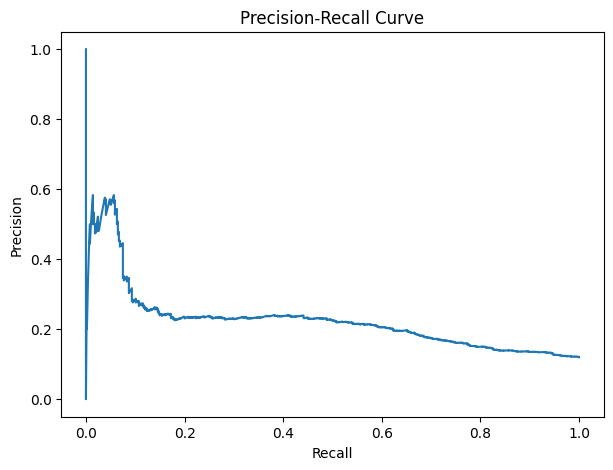

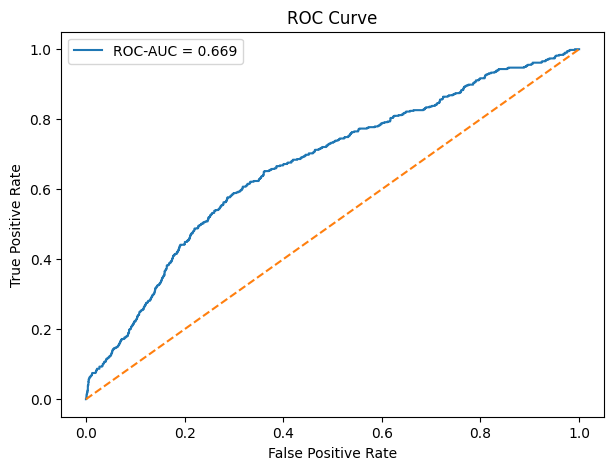

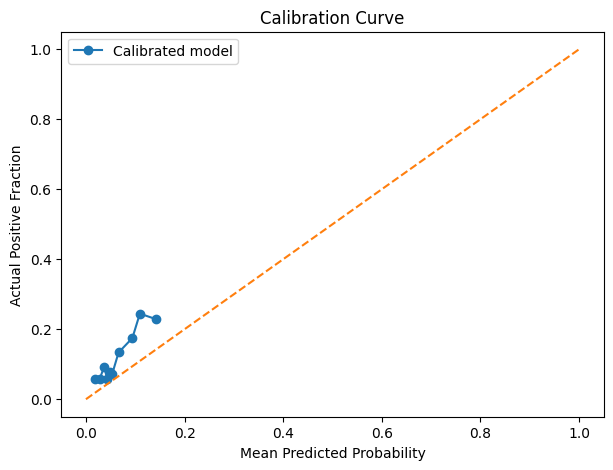


Phase 8 evaluation outputs saved successfully!


In [49]:

# PHASE 8 — CALIBRATION AND EVALUATION

import json
import matplotlib.pyplot as plt

from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

# STEP 1: Calibrate the already-trained model
calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(base_model),
    method="sigmoid"
)

calibrated_model.fit(X_calibration, y_calibration)

print("Calibration completed!")

# STEP 2: Predict on policy validation
probabilities = calibrated_model.predict_proba(
    X_policy_validation
)[:, 1]

predictions = (probabilities >= 0.5).astype(int)

# STEP 3: Calculate metrics
metrics = {
    "average_precision": average_precision_score(
        y_policy_validation, probabilities
    ),
    "roc_auc": roc_auc_score(
        y_policy_validation, probabilities
    ),
    "precision": precision_score(
        y_policy_validation, predictions, zero_division=0
    ),
    "recall": recall_score(
        y_policy_validation, predictions, zero_division=0
    ),
    "f1": f1_score(
        y_policy_validation, predictions, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_policy_validation, predictions
    ),
    "brier_score": brier_score_loss(
        y_policy_validation, probabilities
    ),
    "log_loss": log_loss(
        y_policy_validation, probabilities,
        labels=[0, 1]
    )
}

print("\n========== PHASE 8 METRICS ==========")

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_policy_validation, predictions))

# STEP 4: Precision-Recall curve
precision_values, recall_values, _ = precision_recall_curve(
    y_policy_validation, probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(recall_values, precision_values)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.savefig("evaluation_plots_precision_recall.png")
plt.show()

# STEP 5: ROC curve
fpr, tpr, _ = roc_curve(
    y_policy_validation, probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("evaluation_plots_roc.png")
plt.show()

# STEP 6: Reliability curve
actual_fraction, predicted_fraction = calibration_curve(
    y_policy_validation,
    probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(
    predicted_fraction,
    actual_fraction,
    marker="o",
    label="Calibrated model"
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Positive Fraction")
plt.title("Calibration Curve")
plt.legend()
plt.savefig("evaluation_plots_calibration.png")
plt.show()

# STEP 7: Save model and results
joblib.dump(
    calibrated_model,
    "models/calibrated_logistic_regression.joblib"
)

with open("results/phase8_metrics.json", "w") as f:
    json.dump(
        {k: float(v) for k, v in metrics.items()},
        f,
        indent=4
    )

pd.DataFrame({
    "actual": y_policy_validation.to_numpy(),
    "predicted_probability": probabilities,
    "predicted_class_at_0.5": predictions
}).to_csv(
    "results/phase8_policy_validation_predictions.csv",
    index=False
)

print("\nPhase 8 evaluation outputs saved successfully!")
